# Chương 2 Khám phá trực quan hóa và tiền xử lý CKD
**Huỳnh Công Tạo — MSSV 2001240431 — Nhóm 01**

Notebook thực hiện mục 2.1–2.4: khảo sát dữ liệu, EDA, làm sạch, chia tập,
xây dựng Pipeline chống rò rỉ dữ liệu và bàn giao cho Chương 3–5.

Trên Kaggle: nhập notebook, thêm dataset chứa kidney_disease.csv, chạy các cell từ trên xuống.
Nếu có nhiều file cùng tên, sửa DATA_PATH. CPU là đủ. Module tiền xử lý được tự tạo,
không cần tải file Python riêng. Kết quả ở /kaggle/working/chuong2 và ZIP ở /kaggle/working.

Chỉ kiểm kê chất lượng trên toàn bộ dữ liệu; EDA chi tiết dùng Train. Test dành cho Chương 4.
Notebook chưa huấn luyện hoặc tuyên bố độ chính xác của mô hình.


In [1]:
from pathlib import Path
import sys, json, hashlib, platform, shutil, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, joblib
from IPython.display import display, Markdown, FileLink
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone

RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_PATH = None  # Hoặc Path('/kaggle/input/ten-dataset/kidney_disease.csv')
ON_KAGGLE = Path('/kaggle/input').exists()
OUT = Path('/kaggle/working/chuong2') if ON_KAGGLE else Path.cwd()
for folder in ['data/processed', 'reports/figures', 'reports/tables']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
PROCESSED, FIGURES, TABLES = OUT/'data/processed', OUT/'reports/figures', OUT/'reports/tables'
versions = {m: importlib.import_module(m).__version__ for m in
            ['numpy','pandas','sklearn','matplotlib','seaborn','joblib']}
sns.set_theme(style='whitegrid', palette='Set2', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':170})
print('Python:', platform.python_version(), '\nThư viện:', versions)

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES/f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

def show_table(df, name, index=True):
    df.to_csv(TABLES/f'{name}.csv', index=index, encoding='utf-8-sig')
    display(df)


Matplotlib is building the font cache; this may take a moment.


Python: 3.12.14 
Thư viện: {'numpy': '2.5.4', 'pandas': '3.1.1', 'sklearn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0'}


## Module dùng lại cho huấn luyện và ứng dụng
Cell sau ghi module đi cùng joblib. CKDCleaner chuẩn hóa cú pháp bằng quy tắc cố định.
Median, mode, mean và độ lệch chuẩn được học ở các bước sau, chỉ trên Train.


In [2]:
MODULE_SOURCE = '"""Tiền xử lý CKD — Huỳnh Công Tạo. Module phải đi cùng file joblib."""\nimport numpy as np\nimport pandas as pd\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\n\nFEATURES = [\'age\',\'bp\',\'sg\',\'al\',\'su\',\'rbc\',\'pc\',\'pcc\',\'ba\',\'bgr\',\'bu\',\'sc\',\n            \'sod\',\'pot\',\'hemo\',\'pcv\',\'wc\',\'rc\',\'htn\',\'dm\',\'cad\',\'appet\',\'pe\',\'ane\']\nNUMERIC = [\'age\',\'bp\',\'bgr\',\'bu\',\'sc\',\'sod\',\'pot\',\'hemo\',\'pcv\',\'wc\',\'rc\']\nBINARY = [\'rbc\',\'pc\',\'pcc\',\'ba\',\'htn\',\'dm\',\'cad\',\'appet\',\'pe\',\'ane\']\nMULTI = [\'sg\',\'al\',\'su\']\nBINARY_LEVELS = [[\'normal\',\'abnormal\'], [\'normal\',\'abnormal\'],\n                 [\'notpresent\',\'present\'], [\'notpresent\',\'present\'],\n                 [\'no\',\'yes\'], [\'no\',\'yes\'], [\'no\',\'yes\'],\n                 [\'good\',\'poor\'], [\'no\',\'yes\'], [\'no\',\'yes\']]\nMULTI_LEVELS = [[\'1.005\',\'1.01\',\'1.015\',\'1.02\',\'1.025\'],\n                [\'0\',\'1\',\'2\',\'3\',\'4\',\'5\'], [\'0\',\'1\',\'2\',\'3\',\'4\',\'5\']]\nMISSING = {\'\', \'?\', \'nan\', \'none\', \'null\', \'na\', \'n/a\'}\n\ndef normalize_text(series):\n    """Quy tắc cố định, không học thống kê từ dữ liệu."""\n    return series.map(lambda v: np.nan if pd.isna(v) or str(v).strip().lower() in MISSING\n                      else str(v).strip().lower()).astype(object)\n\nclass CKDCleaner(TransformerMixin, BaseEstimator):\n    """Chuẩn hóa 24 cột; từ chối cột lạ/thiếu và giá trị không hợp lệ."""\n    def fit(self, X, y=None):\n        self.transform(X)\n        self.feature_names_in_ = np.asarray(FEATURES, dtype=object)\n        self.n_features_in_ = len(FEATURES)\n        return self\n\n    def transform(self, X):\n        if not isinstance(X, pd.DataFrame):\n            raise TypeError(\'Đầu vào phải là pandas DataFrame có tên 24 cột.\')\n        if X.columns.duplicated().any() or set(X.columns) != set(FEATURES):\n            raise ValueError(f\'Cần đúng 24 cột. Thiếu={set(FEATURES)-set(X.columns)}, \'\n                             f\'thừa={set(X.columns)-set(FEATURES)}\')\n        out = X.loc[:, FEATURES].copy()\n        for col in FEATURES:\n            out[col] = normalize_text(out[col])\n        for col in NUMERIC + MULTI:\n            val = pd.to_numeric(out[col], errors=\'coerce\')\n            invalid = out[col].notna() & val.isna()\n            if invalid.any():\n                raise ValueError(f\'{col}: giá trị không phải số {out.loc[invalid,col].unique()}\')\n            if ((val.notna()) & (~np.isfinite(val) | (val < 0))).any():\n                raise ValueError(f\'{col}: có giá trị âm hoặc vô hạn.\')\n            out[col] = val.astype(float)\n        for col in MULTI:\n            out[col] = out[col].map(lambda v: np.nan if pd.isna(v) else format(v, \'g\')).astype(object)\n        for col, levels in zip(BINARY + MULTI, BINARY_LEVELS + MULTI_LEVELS):\n            invalid = out[col].notna() & ~out[col].isin(levels)\n            if invalid.any():\n                raise ValueError(f\'{col}: ngoài miền cho phép: {out.loc[invalid,col].unique()}\')\n        return out\n\n    def get_feature_names_out(self, input_features=None):\n        return np.asarray(FEATURES, dtype=object)\n\ndef make_preprocessor():\n    numeric = Pipeline([\n        (\'imputer\', SimpleImputer(strategy=\'median\', keep_empty_features=True)),\n        (\'scaler\', StandardScaler()),\n    ])\n    binary = Pipeline([\n        (\'imputer\', SimpleImputer(strategy=\'most_frequent\', keep_empty_features=True)),\n        (\'encoder\', OneHotEncoder(categories=BINARY_LEVELS, drop=\'if_binary\',\n                                  handle_unknown=\'error\', sparse_output=False)),\n    ])\n    multi = Pipeline([\n        (\'imputer\', SimpleImputer(strategy=\'most_frequent\', keep_empty_features=True)),\n        (\'encoder\', OneHotEncoder(categories=MULTI_LEVELS, drop=None,\n                                  handle_unknown=\'error\', sparse_output=False)),\n    ])\n    columns = ColumnTransformer([\n        (\'num\', numeric, NUMERIC), (\'binary\', binary, BINARY), (\'multi\', multi, MULTI),\n    ], remainder=\'drop\', verbose_feature_names_out=True)\n    return Pipeline([(\'clean\', CKDCleaner()), (\'columns\', columns)])\n'
(OUT/'ckd_preprocessing.py').write_text(MODULE_SOURCE,encoding='utf-8')
sys.path.insert(0, str(OUT.resolve()))
from ckd_preprocessing import FEATURES, NUMERIC, BINARY, MULTI, BINARY_LEVELS, MULTI_LEVELS, CKDCleaner, normalize_text, make_preprocessor


## 2.1 Tổng quan dữ liệu
Nguồn mô tả: [UCI Chronic Kidney Disease](https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease).
UCI công bố 400 mẫu và 24 thuộc tính. File đang dùng có thêm id và classification.
id chỉ dùng truy vết, không phải đặc trưng dự báo.
Chưa xác định được trang Kaggle cụ thể từ metadata của CSV, vì vậy lưu SHA-256 của file thực chạy.


In [3]:
if DATA_PATH is None:
    if ON_KAGGLE:
        candidates = sorted(Path('/kaggle/input').rglob('kidney_disease.csv'))
    else:
        candidates = [p for p in [Path('kidney_disease.csv'), Path('data/raw/kidney_disease.csv')] if p.exists()]
    if len(candidates) != 1:
        raise ValueError(f'Tìm thấy {len(candidates)} file: {candidates}. Hãy đặt DATA_PATH.')
    DATA_PATH = candidates[0]
DATA_PATH = Path(DATA_PATH)
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
assert set(raw.columns) == set(FEATURES + ['id','classification']), 'Sai cấu trúc CSV'
assert raw['id'].is_unique, 'id bị trùng; cần kiểm tra nguồn'
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print('File:', DATA_PATH, '\nKích thước:', raw.shape, '\nSHA-256:', source_sha256)
display(raw.head())


File: kidney_disease.csv 
Kích thước: (400, 26) 
SHA-256: 835c57ec100db2d3751165fae615fec425caf444cca23bab6a853d4c08bf5556


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.02,1.0,0.0,,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.02,4.0,0.0,,normal,notpresent,notpresent,...,38,6000,,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.01,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.01,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [4]:
descriptions = {
 'age':('Tuổi','năm'), 'bp':('Huyết áp','mmHg'),
 'sg':('Tỷ trọng nước tiểu','không đơn vị'), 'al':('Albumin nước tiểu','mức 0–5'),
 'su':('Đường nước tiểu','mức 0–5'), 'rbc':('Hồng cầu trong nước tiểu','normal / abnormal'),
 'pc':('Tế bào mủ','normal / abnormal'), 'pcc':('Cụm tế bào mủ','notpresent / present'),
 'ba':('Vi khuẩn','notpresent / present'), 'bgr':('Đường huyết ngẫu nhiên','mg/dL'),
 'bu':('Urê máu','mg/dL'), 'sc':('Creatinin huyết thanh','mg/dL'),
 'sod':('Natri','mEq/L'), 'pot':('Kali','mEq/L'), 'hemo':('Hemoglobin','gms theo UCI'),
 'pcv':('Thể tích khối hồng cầu','UCI không ghi đơn vị'),
 'wc':('Số lượng bạch cầu','cells/cumm'), 'rc':('Số lượng hồng cầu','millions/cmm'),
 'htn':('Tăng huyết áp','no / yes'), 'dm':('Đái tháo đường','no / yes'),
 'cad':('Bệnh động mạch vành','no / yes'), 'appet':('Sự thèm ăn','good / poor'),
 'pe':('Phù chân','no / yes'), 'ane':('Thiếu máu','no / yes')}
dictionary = pd.DataFrame([{'feature':c,'description':descriptions[c][0],
    'unit_or_values':descriptions[c][1],
    'type':'numeric' if c in NUMERIC else 'binary' if c in BINARY else 'categorical'} for c in FEATURES])
show_table(dictionary, 'data_dictionary', index=False)


,feature,description,unit_or_values,type
0,age,Tuổi,năm,numeric
1,bp,Huyết áp,mmHg,numeric
2,sg,Tỷ trọng nước tiểu,không đơn vị,categorical
3,al,Albumin nước tiểu,mức 0–5,categorical
4,su,Đường nước tiểu,mức 0–5,categorical
5,rbc,Hồng cầu trong nước tiểu,normal / abnormal,binary
6,pc,Tế bào mủ,normal / abnormal,binary
7,pcc,Cụm tế bào mủ,notpresent / present,binary
8,ba,Vi khuẩn,notpresent / present,binary
9,bgr,Đường huyết ngẫu nhiên,mg/dL,numeric


## 2.2.1 đến 2.2.3 Nhãn khuyết thiếu và lỗi định dạng
Đọc chuỗi gốc để phát hiện tab, khoảng trắng và dấu hỏi.
Sau strip và chuyển chữ thường, các token rỗng hoặc ? trở thành NaN.
pcv, wc, rc được chuyển sang số. Giá trị lạ ngoài miền bị báo lỗi, không âm thầm đổi.
Nhãn ckd = 1, notckd = 0. Nhãn thiếu hoặc lạ không được điền mode.


In [5]:
audit = []
for col in FEATURES + ['classification']:
    for value, count in raw[col].value_counts().items():
        if value and (value != value.strip() or '?' in value or '\t' in value):
            audit.append({'column':col,'raw_repr':repr(value),'count':int(count),
                          'normalized':value.strip().lower()})
show_table(pd.DataFrame(audit, columns=['column','raw_repr','count','normalized']), 'format_audit', index=False)
X = CKDCleaner().fit_transform(raw[FEATURES])
target_text = normalize_text(raw['classification'])
assert target_text.notna().all() and target_text.isin(['ckd','notckd']).all(), 'Nhãn thiếu/lạ'
y = target_text.map({'notckd':0,'ckd':1}).astype(int).rename('classification')
duplicates = X.assign(classification=y).duplicated(keep=False)
print('Số dòng trùng thuộc tính và nhãn:', int(duplicates.sum()))
if duplicates.any():
    raise ValueError('Cần xử lý trùng hoặc chia theo nhóm trước khi tiếp tục.')
missing = pd.DataFrame({'missing_before':raw[FEATURES].eq('').sum(),'missing_after':X.isna().sum()})
missing['percent_after'] = (missing['missing_after']/len(X)*100).round(2)
missing['hidden_missing_found'] = missing['missing_after']-missing['missing_before']
show_table(missing.sort_values('missing_after', ascending=False), 'missing_all')
class_counts = y.value_counts().reindex([0,1])
show_table(pd.DataFrame({'label':['notckd','ckd'],'count':class_counts.values,
    'percent':class_counts.values/len(y)*100}), 'class_distribution_all', index=False)
print('Dòng đủ 24 thuộc tính:', int(X.notna().all(axis=1).sum()))


,column,raw_repr,count,normalized
0,pcv,'\t?',1,?
1,pcv,'\t43',1,43
2,wc,'\t6200',1,6200
3,wc,'\t8400',1,8400
4,wc,'\t?',1,?
5,rc,'\t?',1,?
6,dm,'\tno',3,no
7,dm,'\tyes',2,yes
8,dm,' yes',1,yes
9,cad,'\tno',2,no


Số dòng trùng thuộc tính và nhãn: 0


,missing_before,missing_after,percent_after,hidden_missing_found
rbc,152,152,38.00,0
rc,130,131,32.75,1
wc,105,106,26.50,1
pot,88,88,22.00,0
sod,87,87,21.75,0
pcv,70,71,17.75,1
pc,65,65,16.25,0
hemo,52,52,13.00,0
su,49,49,12.25,0
sg,47,47,11.75,0


,label,count,percent
0,notckd,150,37.5
1,ckd,250,62.5


Dòng đủ 24 thuộc tính: 158


## 2.3.6 Chia tập trước EDA chi tiết và fit
Train 80%, Test 20%, stratify=y, random_state=42. Các phép làm sạch trước đó không học
thống kê từ dữ liệu. Sau đây, phân phối, ngoại lai và tương quan được khảo sát chỉ trên Train.


,all,train,test
classification,,,
0,150,120,30
1,250,200,50


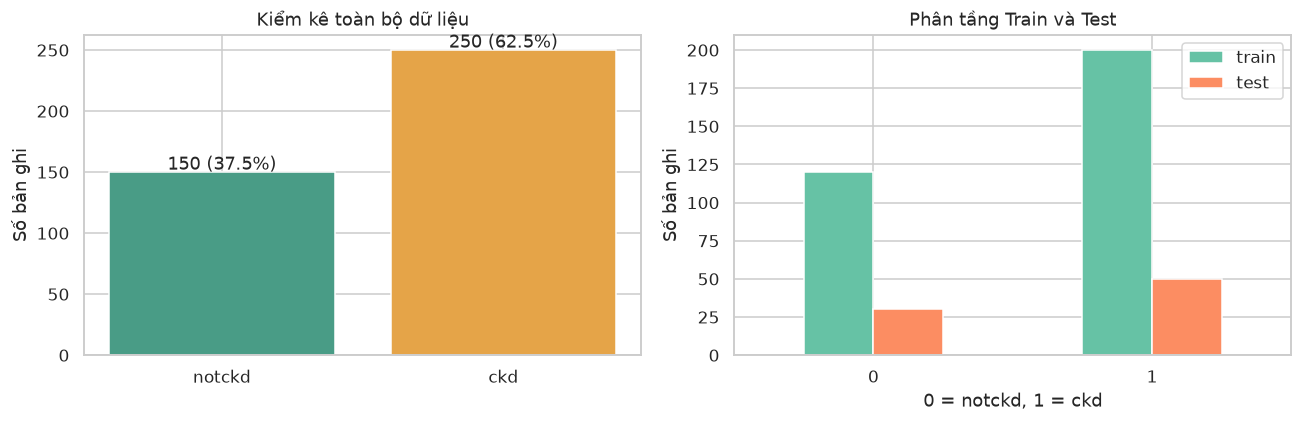

In [6]:
train_idx, test_idx = train_test_split(np.arange(len(X)), test_size=TEST_SIZE,
                                      stratify=y, random_state=RANDOM_STATE)
X_train_raw, X_test_raw = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
assert not set(train_idx).intersection(test_idx)
assert len(train_idx)+len(test_idx) == len(raw)
assert X_train_raw.notna().any().all(), 'Train có cột thiếu hoàn toàn'
split_summary = pd.DataFrame({'all':y.value_counts(),'train':y_train.value_counts(),
                              'test':y_test.value_counts()}).sort_index()
show_table(split_summary, 'split_summary')
eda = X_train_raw.assign(classification=y_train.map({0:'notckd',1:'ckd'}))
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(['notckd','ckd'], class_counts.values, color=['#499c86','#e5a448'])
axes[0].set(title='Kiểm kê toàn bộ dữ liệu',ylabel='Số bản ghi')
for i,v in enumerate(class_counts.values):
    axes[0].text(i,v+2,f'{v} ({v/len(y):.1%})',ha='center')
split_summary[['train','test']].plot.bar(ax=axes[1],rot=0)
axes[1].set(title='Phân tầng Train và Test',xlabel='0 = notckd, 1 = ckd',ylabel='Số bản ghi')
save_figure('01_class_split')


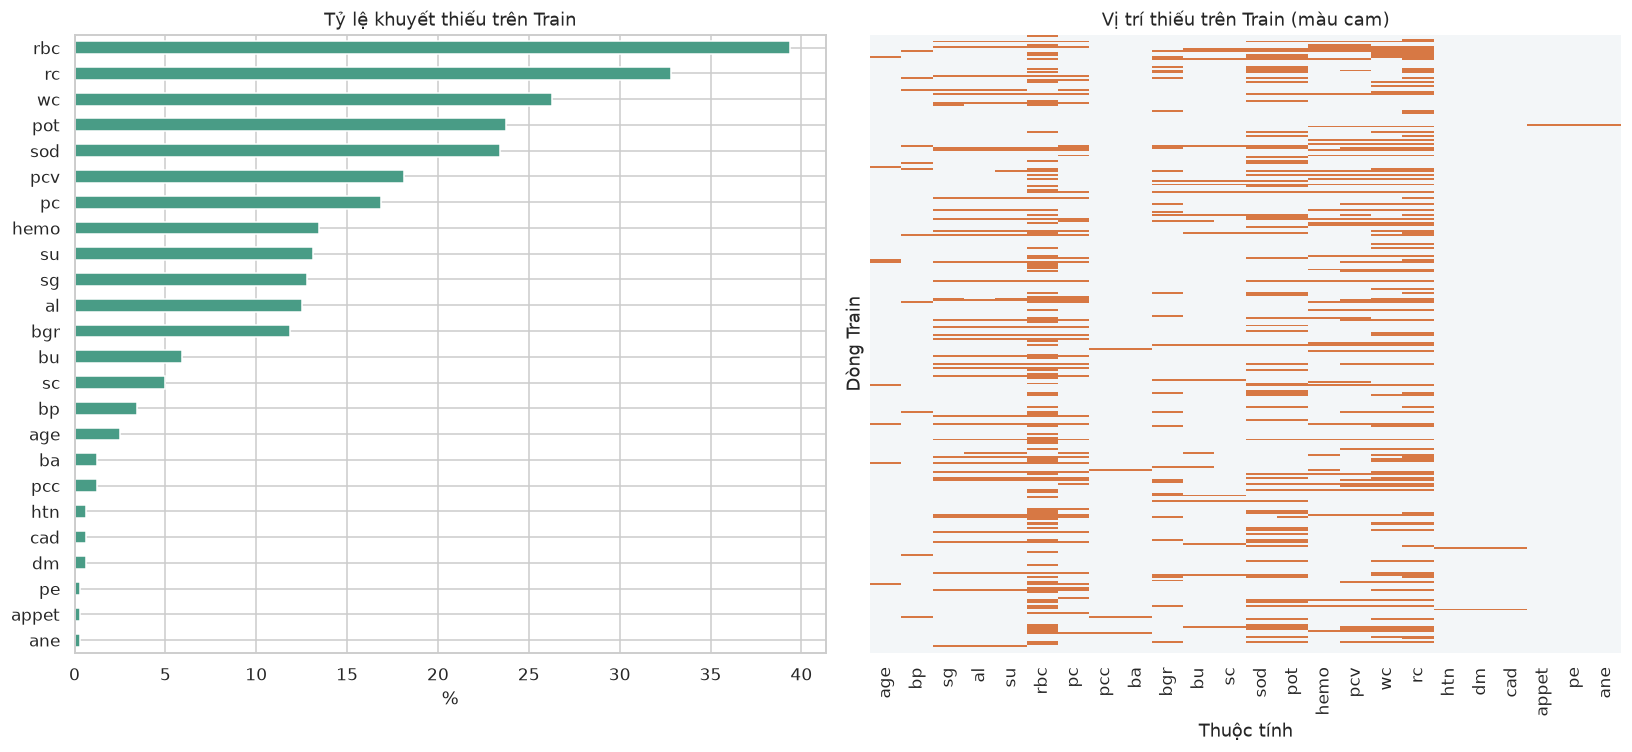

,count,mean,std,min,25%,50%,75%,max
age,312.0,51.086538,17.156989,2.0,42.0,54.0,64.0,90.0
bp,309.0,76.763754,14.183830,50.0,70.0,80.0,80.0,180.0
bgr,282.0,145.053191,75.856678,22.0,100.0,120.5,156.0,490.0
bu,301.0,57.445847,49.632905,1.5,27.0,42.0,66.0,322.0
sc,304.0,3.148355,6.049149,0.4,0.9,1.2,2.9,76.0
sod,245.0,137.042857,11.104718,4.5,135.0,138.0,142.0,150.0
pot,244.0,4.352459,0.756178,2.5,3.8,4.3,4.9,7.6
hemo,277.0,12.518773,2.972667,3.1,10.4,12.6,15.0,17.8
pcv,262.0,38.675573,8.992850,9.0,32.0,40.0,45.0,54.0
wc,236.0,8403.813559,3084.654240,2200.0,6300.0,8100.0,9800.0,26400.0


In [7]:
fig, axes = plt.subplots(1,2,figsize=(15,7))
(X_train_raw.isna().mean().sort_values()*100).plot.barh(ax=axes[0],color='#499c86')
axes[0].set(title='Tỷ lệ khuyết thiếu trên Train',xlabel='%')
sns.heatmap(X_train_raw.isna(),cbar=False,yticklabels=False,
            cmap=['#f3f6f8','#d77844'],ax=axes[1])
axes[1].set(title='Vị trí thiếu trên Train (màu cam)',xlabel='Thuộc tính',ylabel='Dòng Train')
save_figure('02_missing_train')
show_table(X_train_raw[NUMERIC].describe().T, 'numeric_summary_train')


## 2.2.4 Phân phối và ngoại lai
Histogram và boxplot dùng giá trị quan sát trước điền khuyết.
Điểm vượt Q1 − 1.5×IQR hoặc Q3 + 1.5×IQR là cờ kiểm tra, không có nghĩa chắc chắn bị sai.
Không tự xóa hay cắt giá trị lớn. Không có hồ sơ gốc để xác minh mọi ngoại lai đều hợp lệ
về lâm sàng; giữ chúng trong bộ dữ liệu và ghi nhận hạn chế này.


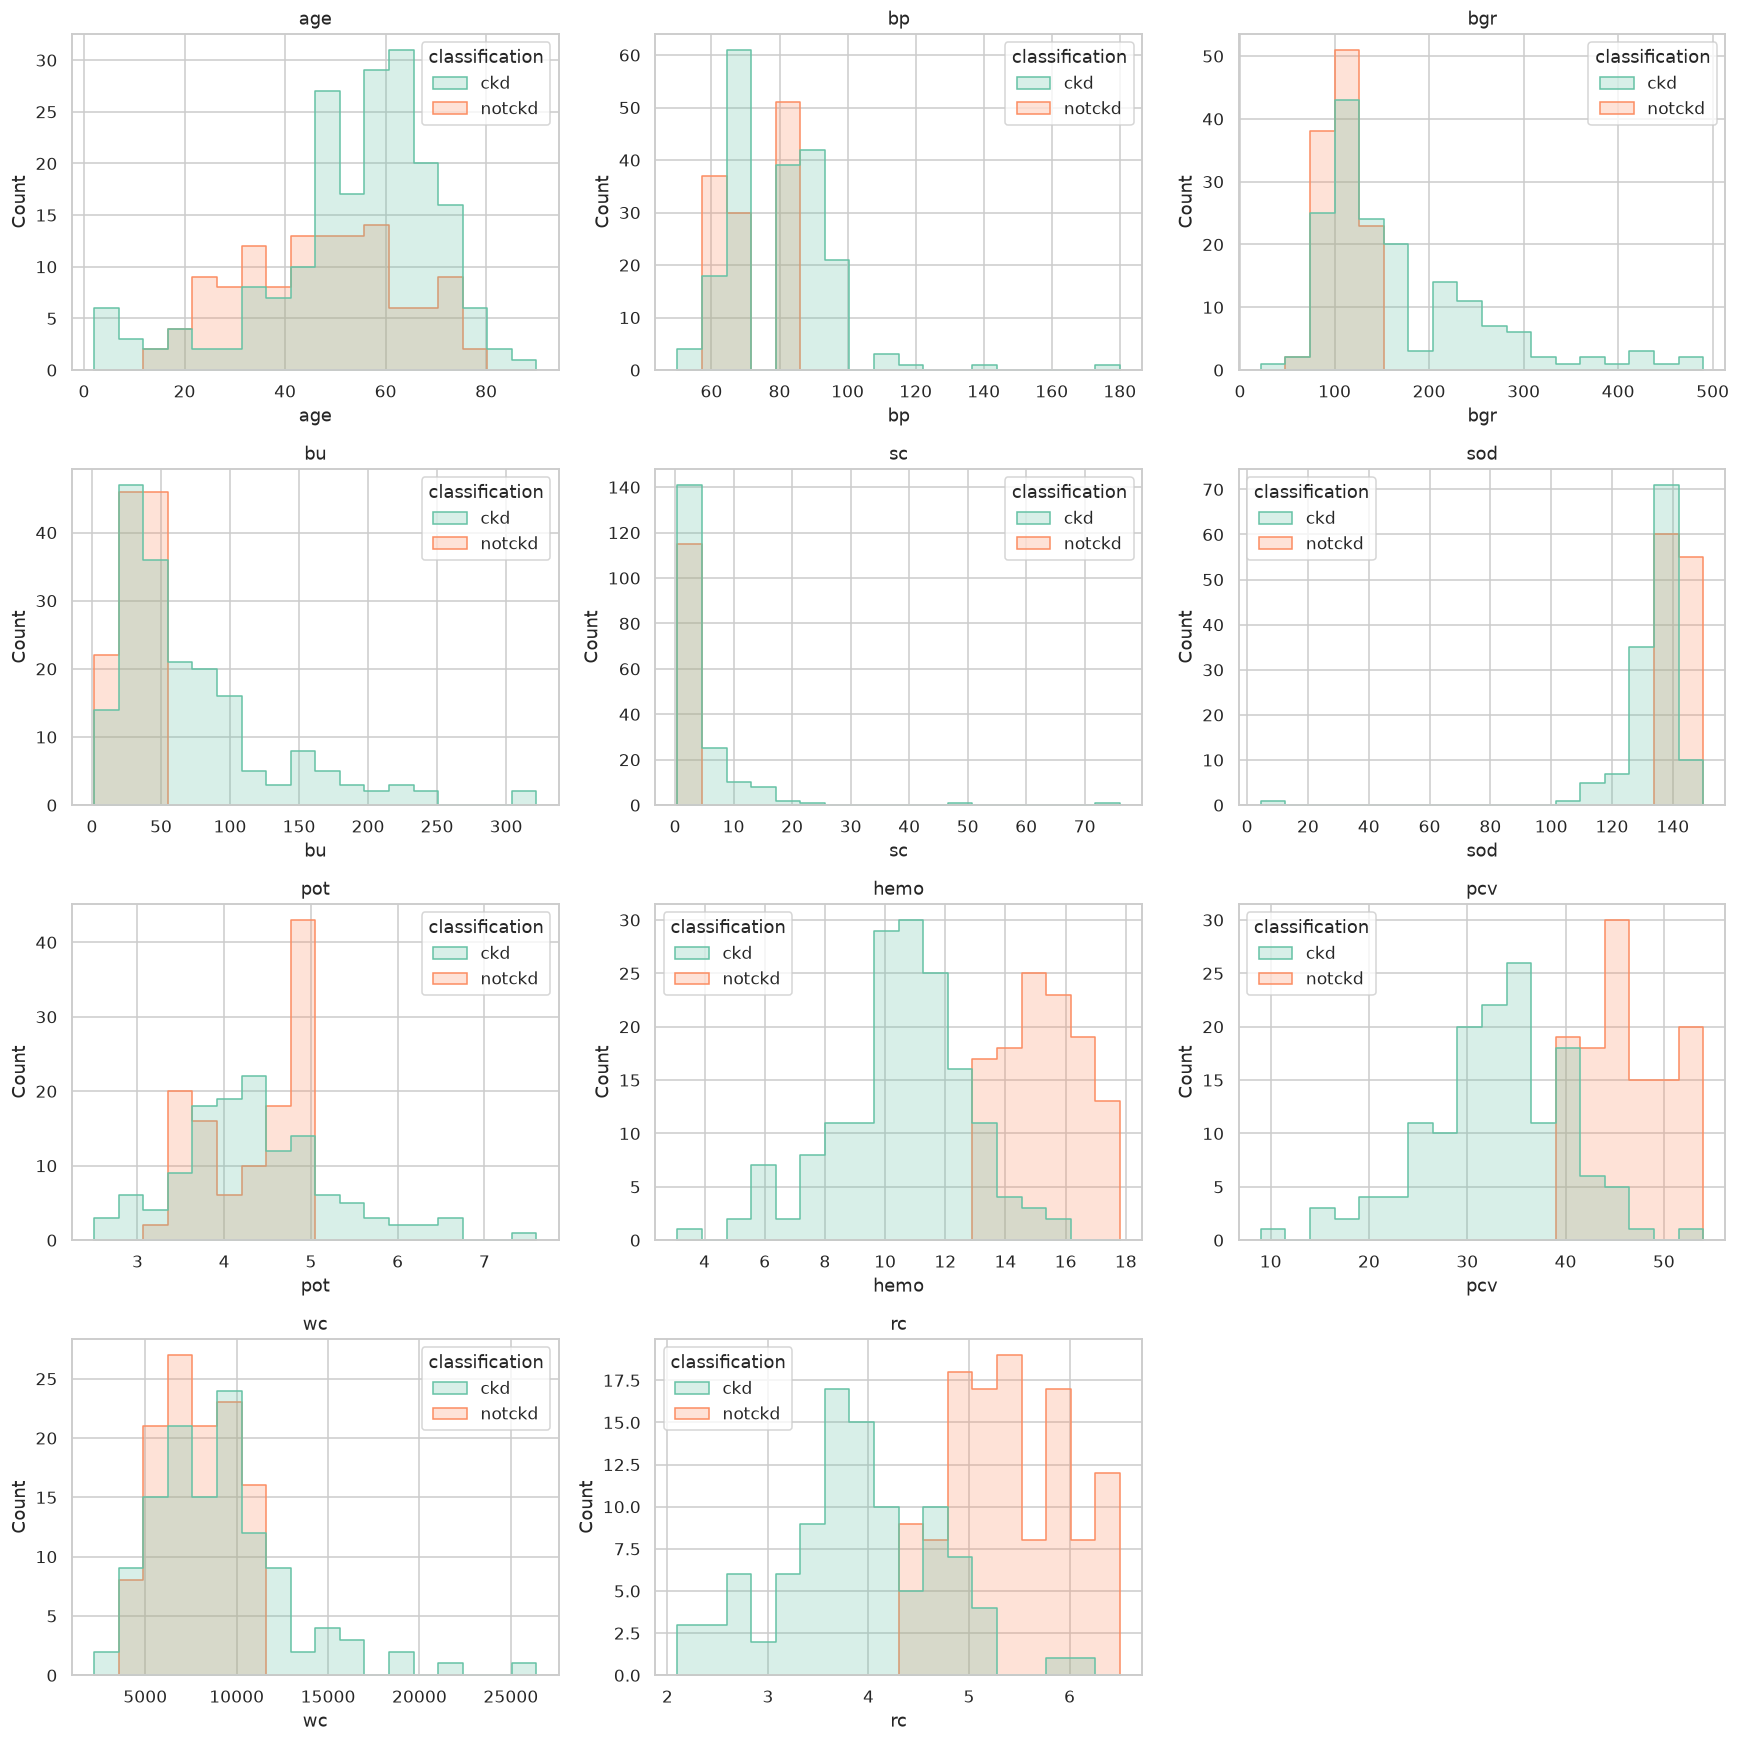

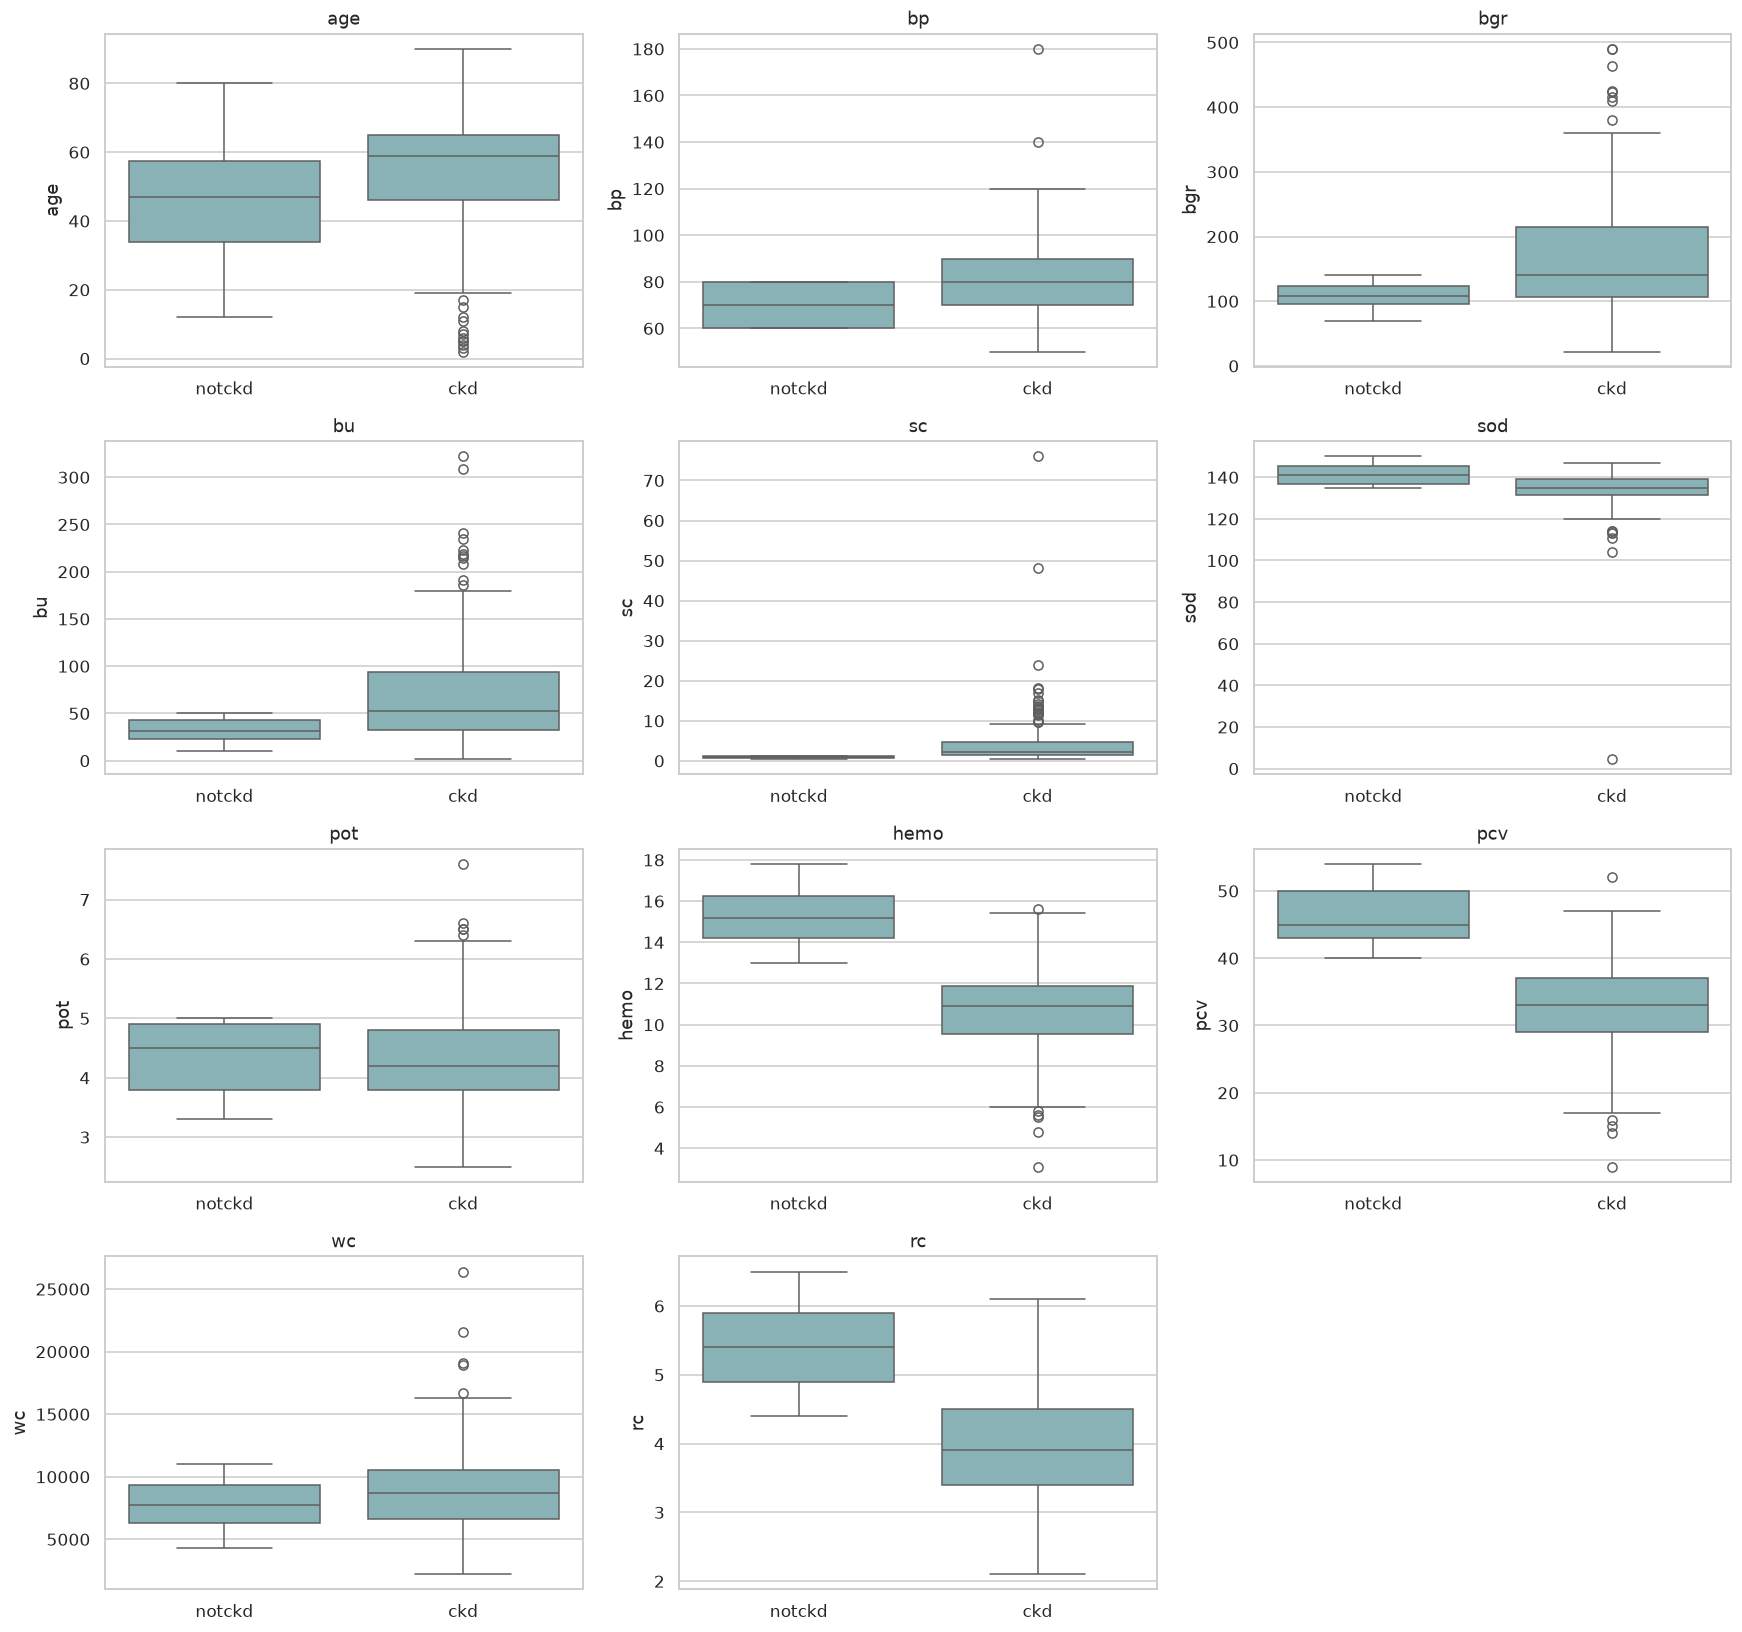

,feature,q1,q3,lower,upper,flagged,observed,percent_observed,min,max
0,age,42.0,64.0,9.00,97.00,8,312,2.56,2.0,90.0
1,bp,70.0,80.0,55.00,95.00,31,309,10.03,50.0,180.0
2,bgr,100.0,156.0,16.00,240.00,33,282,11.70,22.0,490.0
3,bu,27.0,66.0,-31.50,124.50,29,301,9.63,1.5,322.0
4,sc,0.9,2.9,-2.10,5.90,42,304,13.82,0.4,76.0
5,sod,135.0,142.0,124.50,152.50,12,245,4.90,4.5,150.0
6,pot,3.8,4.9,2.15,6.55,2,244,0.82,2.5,7.6
7,hemo,10.4,15.0,3.50,21.90,1,277,0.36,3.1,17.8
8,pcv,32.0,45.0,12.50,64.50,1,262,0.38,9.0,54.0
9,wc,6300.0,9800.0,1050.00,15050.00,8,236,3.39,2200.0,26400.0


In [8]:
fig, axes = plt.subplots(4,3,figsize=(16,16))
for col,ax in zip(NUMERIC,axes.flat):
    sns.histplot(data=eda,x=col,hue='classification',bins=18,element='step',
                 stat='count',common_norm=False,ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(NUMERIC):]: ax.set_visible(False)
save_figure('03_histograms_train')
fig, axes = plt.subplots(4,3,figsize=(16,15))
for col,ax in zip(NUMERIC,axes.flat):
    sns.boxplot(data=eda,x='classification',y=col,order=['notckd','ckd'],ax=ax,color='#80b8bd')
    ax.set(xlabel='',title=col)
for ax in axes.flat[len(NUMERIC):]: ax.set_visible(False)
save_figure('04_boxplots_train')
outliers = []
for col in NUMERIC:
    values = X_train_raw[col].dropna()
    q1,q3 = values.quantile([.25,.75]); iqr = q3-q1
    lo,hi = q1-1.5*iqr,q3+1.5*iqr
    flags = (values<lo)|(values>hi)
    outliers.append({'feature':col,'q1':q1,'q3':q3,'lower':lo,'upper':hi,
                     'flagged':int(flags.sum()),'observed':len(values),
                     'percent_observed':round(flags.mean()*100,2),
                     'min':values.min(),'max':values.max()})
show_table(pd.DataFrame(outliers), 'outliers_iqr_train', index=False)


## 2.2.5 Tương quan và biến phân loại
Pearson mô tả liên hệ tuyến tính; Spearman mô tả liên hệ đơn điệu theo thứ hạng.
Mỗi cặp chỉ dùng các dòng có đủ cả hai giá trị, vì vậy có bảng số quan sát từng cặp.
Tương quan không chứng minh nhân quả hoặc độ quan trọng mô hình. Không loại biến theo heatmap.


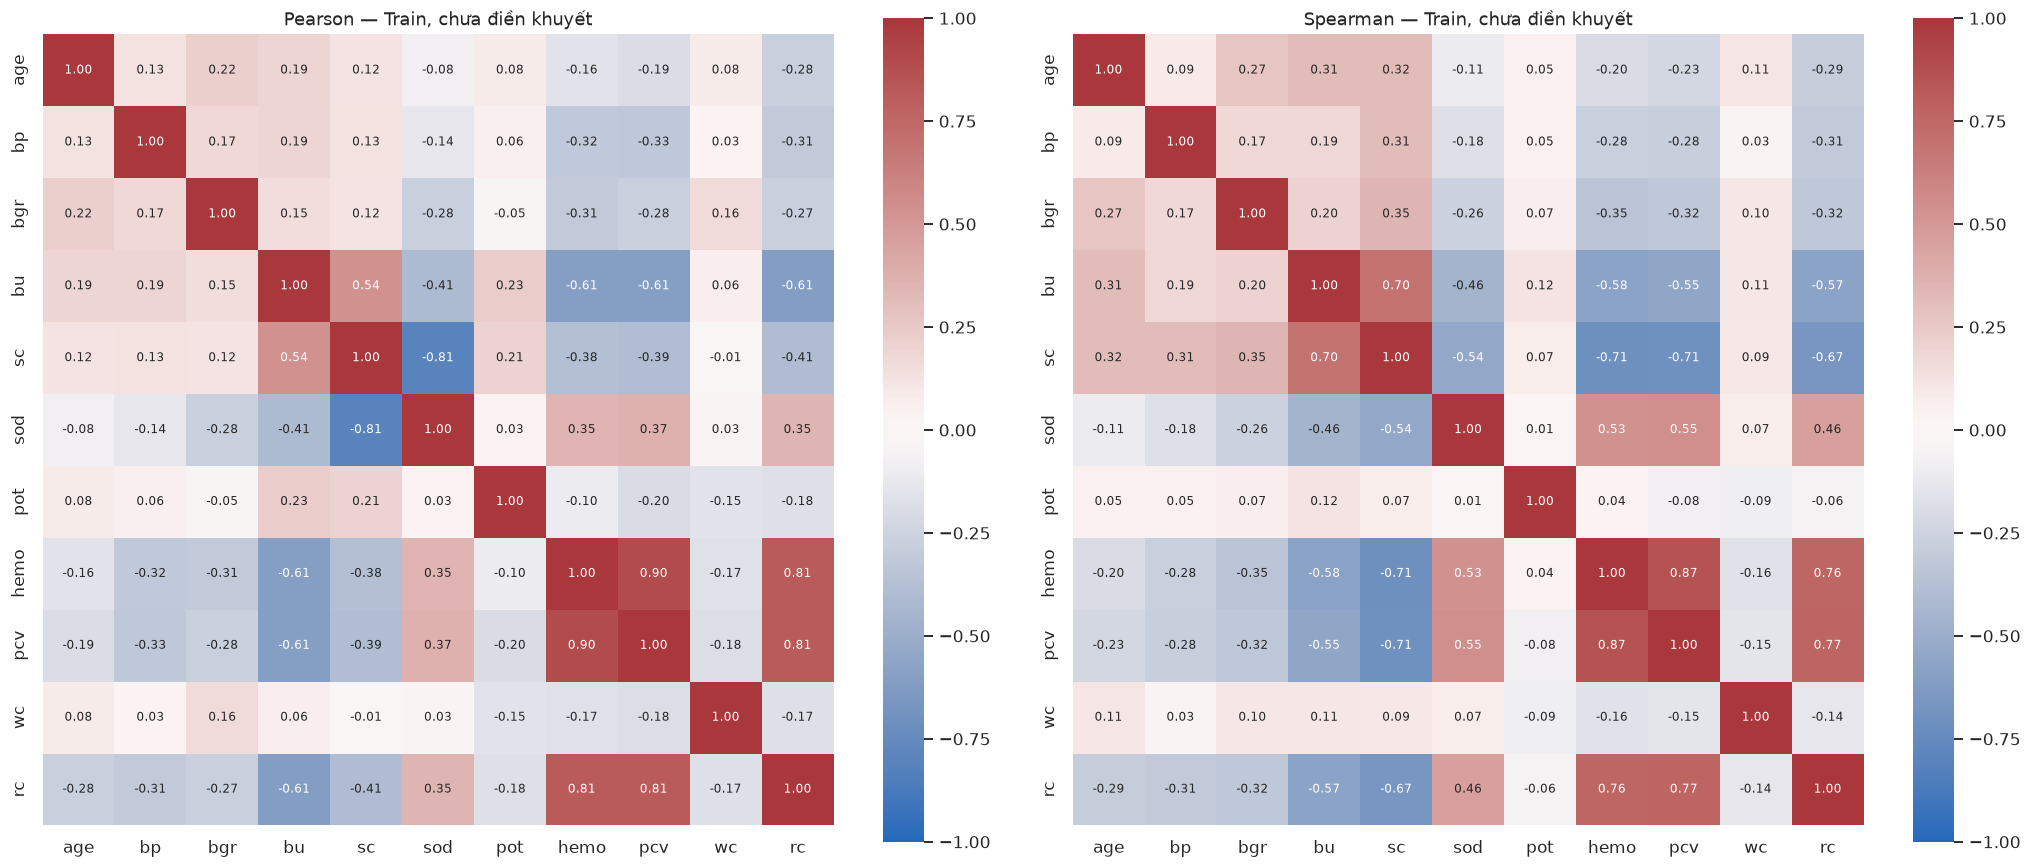

,age,bp,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc
age,312,301,275,293,296,239,238,271,257,232,212
bp,301,309,275,292,295,238,237,268,254,230,210
bgr,275,275,282,277,278,230,230,246,238,212,200
bu,293,292,277,301,301,239,238,264,251,224,206
sc,296,295,278,301,304,242,241,267,254,227,209
sod,239,238,230,239,242,245,244,222,214,195,188
pot,238,237,230,238,241,244,244,221,213,194,187
hemo,271,268,246,264,267,222,221,277,260,231,211
pcv,257,254,238,251,254,214,213,260,262,230,212
wc,232,230,212,224,227,195,194,231,230,236,215


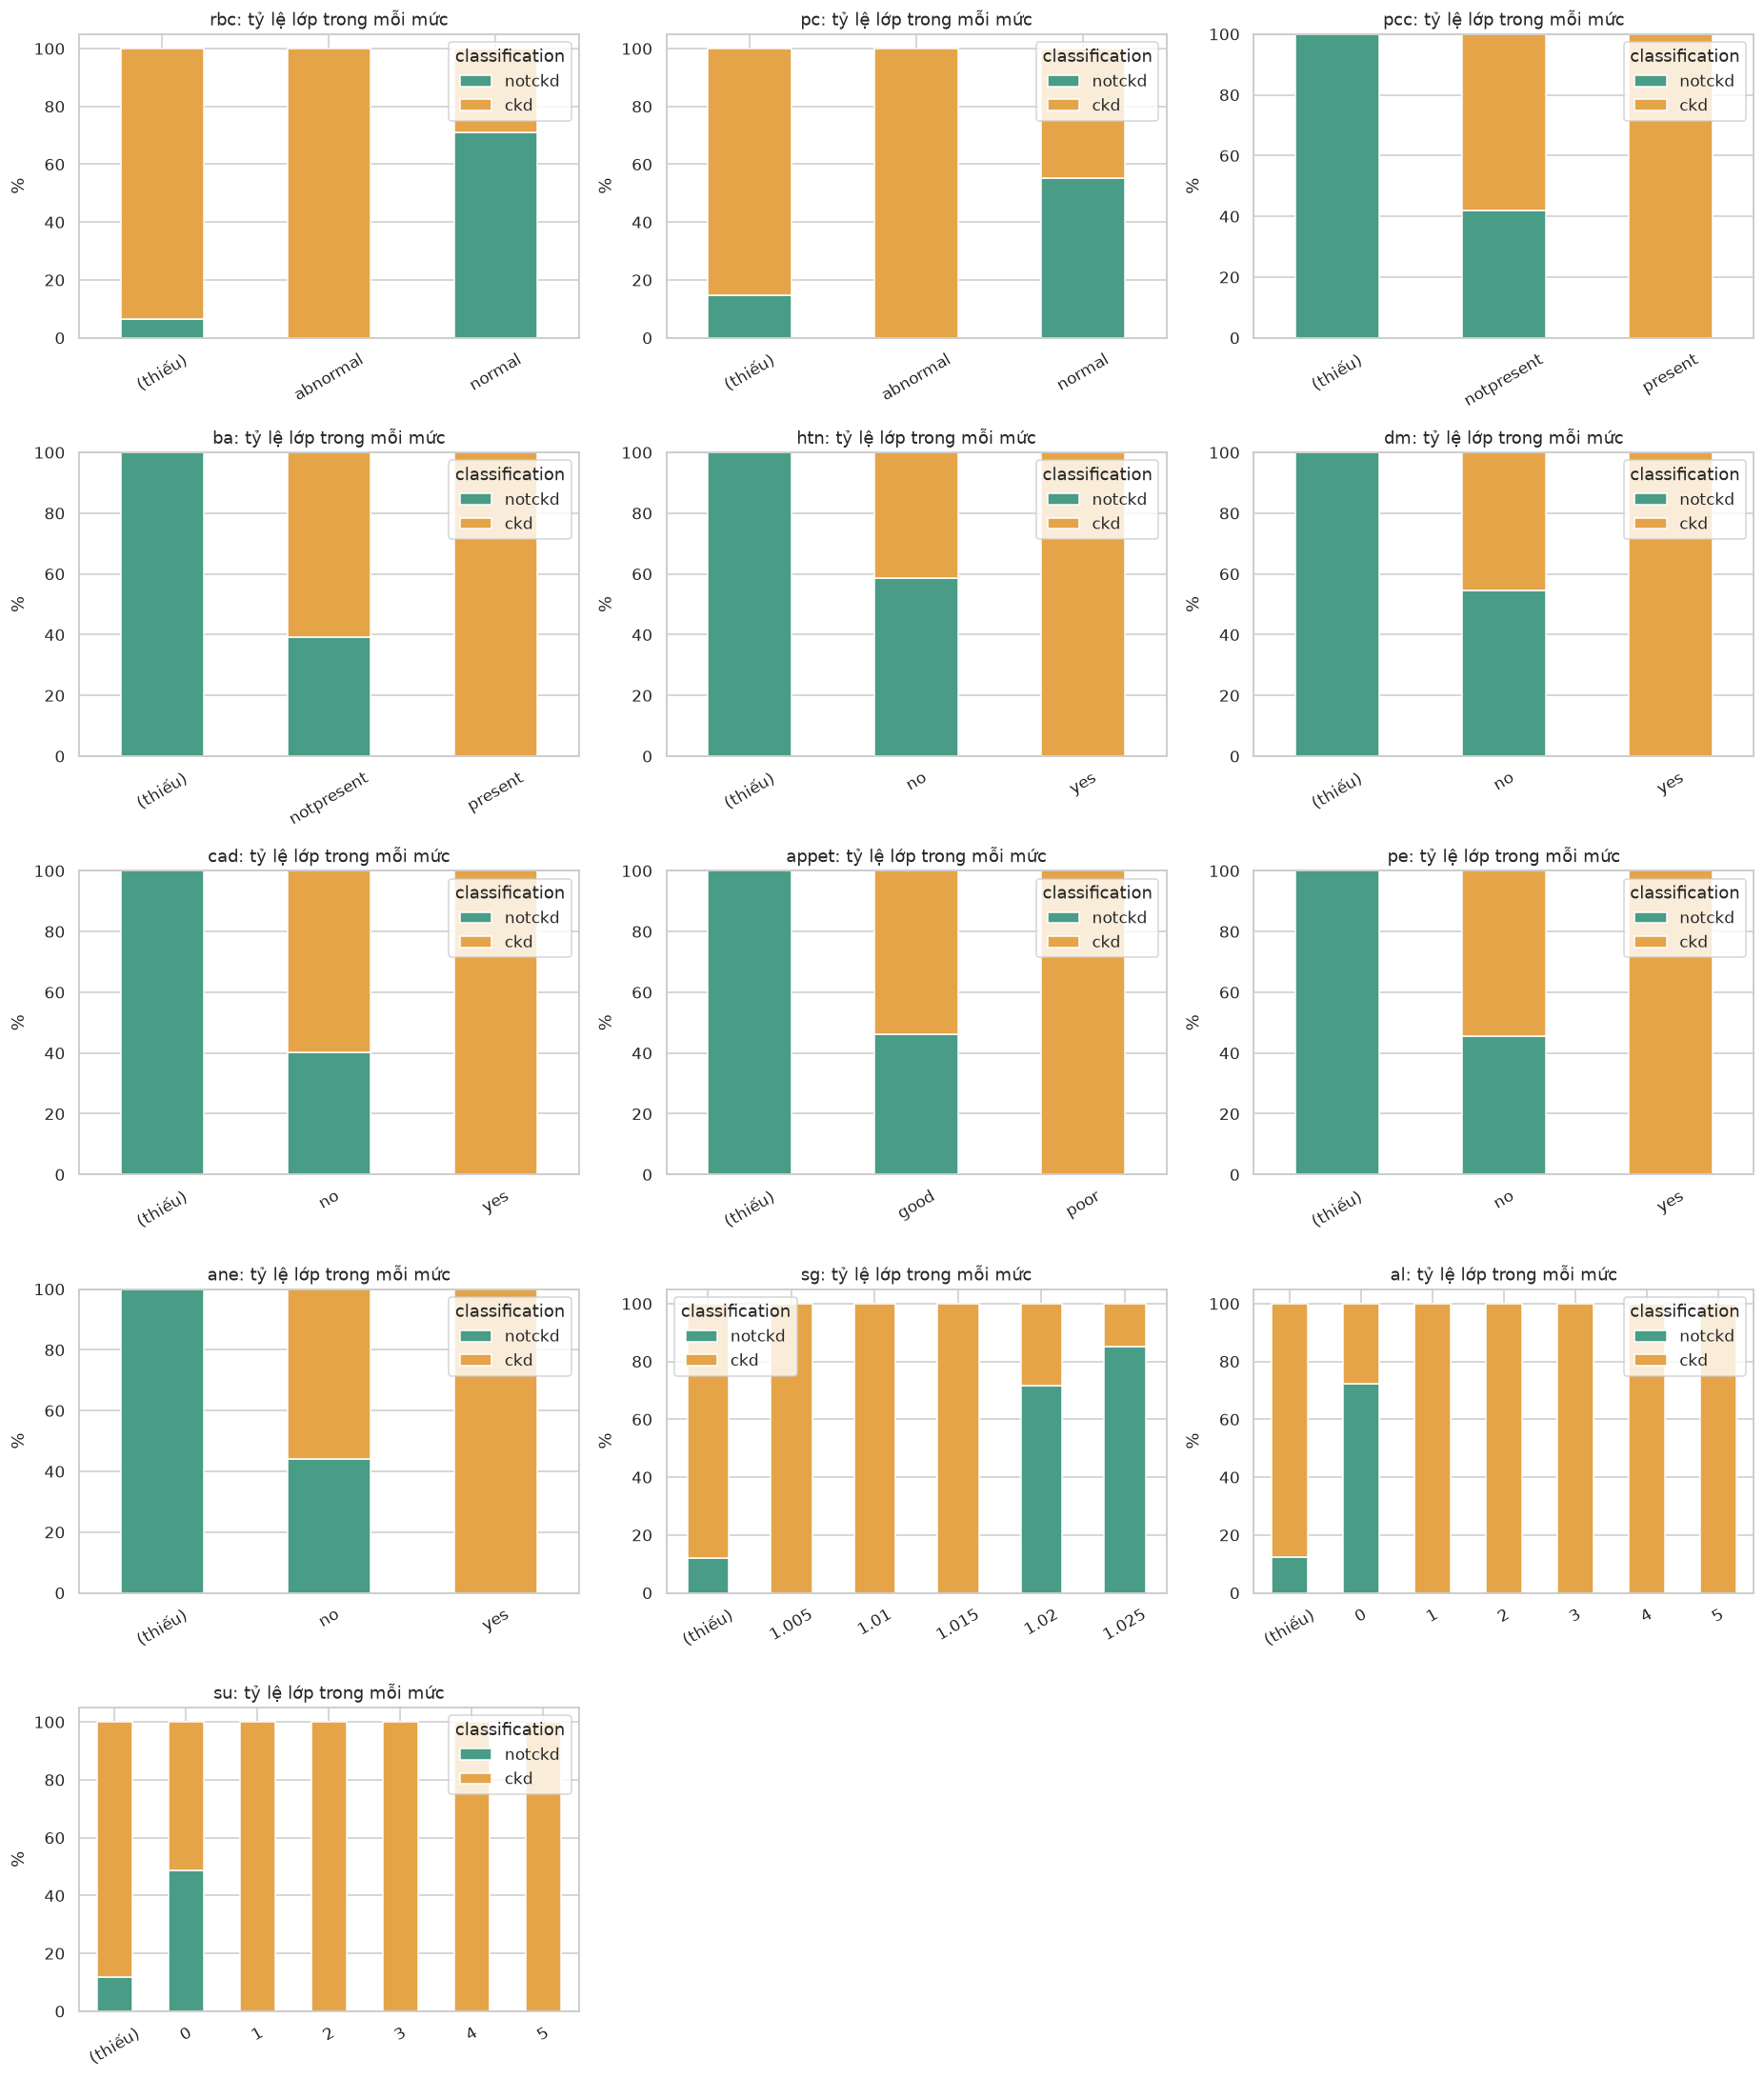

In [9]:
fig,axes = plt.subplots(1,2,figsize=(19,8))
for method,ax in zip(['pearson','spearman'],axes):
    corr = X_train_raw[NUMERIC].corr(method=method)
    corr.to_csv(TABLES/f'correlation_{method}_train.csv')
    sns.heatmap(corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',
                square=True,annot_kws={'size':8},ax=ax)
    ax.set_title(f'{method.title()} — Train, chưa điền khuyết')
save_figure('05_correlations_train')
observed = X_train_raw[NUMERIC].notna().astype(int)
show_table(observed.T @ observed, 'correlation_pair_counts_train')
fig,axes = plt.subplots(5,3,figsize=(17,20))
for col,ax in zip(BINARY+MULTI,axes.flat):
    tab = pd.crosstab(eda[col].fillna('(thiếu)'),eda['classification'],normalize='index')*100
    tab = tab.reindex(columns=['notckd','ckd'],fill_value=0)
    tab.plot.bar(stacked=True,ax=ax,rot=30,color=['#499c86','#e5a448'])
    ax.set(title=f'{col}: tỷ lệ lớp trong mỗi mức',ylabel='%',xlabel='')
for ax in axes.flat[len(BINARY+MULTI):]: ax.set_visible(False)
save_figure('06_categorical_train')


## 2.3 Chiến lược tiền xử lý
- 11 biến số: median Train → StandardScaler Train.
- 10 biến nhị phân: mode Train → OneHotEncoder bỏ mức đầu, còn 1 cột mỗi biến.
- sg, al, su: mode Train → One-Hot đầy đủ theo miền quy định sẵn, lần lượt 5, 6, 6 cột.

StandardScaler dùng z = (x − μ_train)/σ_train; σ tính với ddof=0 sau điền khuyết.
Median ít nhạy với ngoại lai hơn mean. KNNImputer cần chọn số láng giềng và xử lý thang đo;
chưa so sánh bằng CV nên không tuyên bố KNN tốt hơn. Chọn median làm phương án cơ sở.

**24 đầu vào → 38 đầu ra = 11 + 10 + 5 + 6 + 6.**
Các mức phân loại được quy định trước theo từ điển, không lấy từ Test.
Nhãn và id không có trong Pipeline. Không SMOTE hoặc chọn đặc trưng ở Chương 2.


In [10]:
preprocessor = make_preprocessor()
train_array = preprocessor.fit_transform(X_train_raw)
test_array = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out().tolist()
X_train = pd.DataFrame(train_array,columns=feature_names,index=X_train_raw.index)
X_test = pd.DataFrame(test_array,columns=feature_names,index=X_test_raw.index)
assert len(feature_names)==38 and len(set(feature_names))==38
assert np.isfinite(train_array).all() and np.isfinite(test_array).all()
print('Train:',X_train.shape,'| Test:',X_test.shape)
display(X_train.head())
learned_num = preprocessor.named_steps['columns'].named_transformers_['num']
params = pd.DataFrame({'feature':NUMERIC,
    'median_train':learned_num.named_steps['imputer'].statistics_,
    'mean_after_imputation':learned_num.named_steps['scaler'].mean_,
    'scale_after_imputation':learned_num.named_steps['scaler'].scale_})
show_table(params,'learned_numeric_parameters',index=False)
modes = []
for branch,cols in [('binary',BINARY),('multi',MULTI)]:
    imp = preprocessor.named_steps['columns'].named_transformers_[branch].named_steps['imputer']
    modes.extend({'feature':c,'mode_train':v} for c,v in zip(cols,imp.statistics_))
show_table(pd.DataFrame(modes),'learned_modes',index=False)


Train: (320, 38) | Test: (80, 38)


,num__age,num__bp,num__bgr,num__bu,num__sc,num__sod,num__pot,num__hemo,num__pcv,num__wc,...,multi__al_2,multi__al_3,multi__al_4,multi__al_5,multi__su_0,multi__su_1,multi__su_2,multi__su_3,multi__su_4,multi__su_5
108,-0.364027,0.224371,-0.491252,-0.861677,-0.347524,0.384618,-0.212338,-0.264295,-0.235403,0.708759,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
210,0.463391,1.660345,1.577914,1.565947,1.651943,-0.233604,2.062708,-1.894210,-2.324464,0.557632,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
137,-0.364027,-1.211603,1.759665,0.611497,0.160815,-0.336641,1.152690,-0.916261,-1.218491,0.330943,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
148,1.054403,-1.211603,0.403522,-0.633439,7.633399,0.075507,-0.060668,0.025467,0.133254,-0.084654,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
246,-0.186723,2.378332,-0.505233,3.288107,2.058614,-1.779159,2.062708,-1.423346,-1.587148,-1.255883,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


,feature,median_train,mean_after_imputation,scale_after_imputation
0,age,54.0,51.159375,16.920113
1,bp,80.0,76.875000,13.927827
2,bgr,120.5,142.137500,71.526404
3,bu,42.0,56.528750,48.195285
4,sc,1.2,3.050937,5.901573
5,sod,138.0,137.267188,9.705251
6,pot,4.3,4.340000,0.659327
7,hemo,12.6,12.529687,2.760881
8,pcv,40.0,38.915625,8.137629
9,wc,8100.0,8324.062500,2646.793295


,feature,mode_train
0,rbc,normal
1,pc,normal
2,pcc,notpresent
3,ba,notpresent
4,htn,no
5,dm,no
6,cad,no
7,appet,good
8,pe,no
9,ane,no


## 2.4 Quy chuẩn bàn giao
X_train.csv và X_test.csv là ma trận số đã biến đổi, không còn NaN.
X_train_raw.csv và X_test_raw.csv đã sạch cú pháp, vẫn còn NaN để fit riêng trong mỗi fold.
split_manifest.csv lưu id và số dòng tương ứng trong từng file. Không đưa các cột truy vết vào model.
preprocessor.joblib chứa toàn bộ bước làm sạch và tiền xử lý fit trên Train, chưa có classifier.


In [11]:
for name,frame in [('X_train_raw',X_train_raw),('X_test_raw',X_test_raw),
                   ('X_train',X_train),('X_test',X_test),('y_train',y_train),('y_test',y_test)]:
    frame.to_csv(PROCESSED/f'{name}.csv',index=False,encoding='utf-8-sig')
manifest = pd.concat([pd.DataFrame({'split':name,'position':np.arange(len(idx)),
                                   'source_row':idx,'id':raw.iloc[idx]['id'].to_numpy()})
                      for name,idx in [('train',train_idx),('test',test_idx)]],ignore_index=True)
manifest.to_csv(PROCESSED/'split_manifest.csv',index=False)
joblib.dump(preprocessor,OUT/'preprocessor.joblib')
contract = {
 'author':'Huỳnh Công Tạo','student_id':'2001240431','source_file':str(DATA_PATH),'sha256':source_sha256,
 'input_features':FEATURES,'numeric_features':NUMERIC,
 'binary_levels':dict(zip(BINARY,BINARY_LEVELS)),'multi_levels':dict(zip(MULTI,MULTI_LEVELS)),
 'output_features':feature_names,'input_count':len(FEATURES),'output_count':len(feature_names),
 'target_mapping':{'notckd':0,'ckd':1},'random_state':RANDOM_STATE,'test_size':TEST_SIZE,
 'train_rows':len(X_train),'test_rows':len(X_test),'versions':versions,
 'python_version':platform.python_version(),'fit_scope':'train only',
 'unknown_category_policy':'raise ValueError',
 'cv_input':'X_train_raw.csv; fit full Pipeline separately inside each CV fold',
 'load_requires':['ckd_preprocessing.py on sys.path','matching dependency versions']}
(OUT/'feature_contract.json').write_text(json.dumps(contract,ensure_ascii=False,indent=2),encoding='utf-8')
package_names = {'sklearn':'scikit-learn'}
(OUT/'requirements_runtime.txt').write_text('\n'.join(
    f'{package_names.get(k,k)}=={v}' for k,v in versions.items())+'\n',encoding='utf-8')
print('Đã lưu dữ liệu và preprocessor vào', OUT.resolve())


Đã lưu dữ liệu và preprocessor vào D:\baitap\hocmay


### Kiểm tra dữ liệu và khả năng tải lại
Kiểm tra không trùng dòng Train–Test, không có NaN/Inf, median đúng Train, tải lại joblib cho
cùng kết quả, CSV lưu đúng thứ tự và đảo cột đầu vào vẫn hoạt động nhờ chọn theo tên.
Ở từng fold, kiểm tra median chỉ được học từ phần huấn luyện của fold.


In [12]:
loaded = joblib.load(OUT/'preprocessor.joblib')
np.testing.assert_allclose(loaded.transform(X_test_raw),test_array)
np.testing.assert_allclose(loaded.transform(X_test_raw[FEATURES[::-1]]),test_array)
np.testing.assert_allclose(learned_num.named_steps['imputer'].statistics_,
                           X_train_raw[NUMERIC].median().to_numpy())
for name,expected in [('X_train',train_array),('X_test',test_array)]:
    restored = pd.read_csv(PROCESSED/f'{name}.csv')
    assert restored.columns.tolist()==feature_names
    np.testing.assert_allclose(restored.to_numpy(),expected,atol=1e-12)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
for fold,(fit_idx,valid_idx) in enumerate(cv.split(X_train_raw,y_train),start=1):
    fold_prep = make_preprocessor().fit(X_train_raw.iloc[fit_idx])
    actual = fold_prep.named_steps['columns'].named_transformers_['num'].named_steps['imputer'].statistics_
    np.testing.assert_allclose(actual,X_train_raw.iloc[fit_idx][NUMERIC].median().to_numpy())
    assert np.isfinite(fold_prep.transform(X_train_raw.iloc[valid_idx])).all()
verification = {'status':'passed','folds_checked':5,
 'checks':['disjoint split','finite matrices','38 unique features','train-only median',
           'joblib reload','CSV round trip','column order','fold-only median']}
(OUT/'verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
print('PASS — toàn bộ kiểm tra hoàn tất.')


PASS — toàn bộ kiểm tra hoàn tất.


### Hướng dẫn Chương 3 và Web
Không đưa X_train.csv đã fit tiền xử lý trên toàn Train vào 5-fold CV vì fold validation đã
ảnh hưởng median, mode và scaler. Sử dụng X_train_raw.csv với Pipeline đầy đủ như sau.
Đây là mẫu bàn giao, chưa phải kết quả huấn luyện của Chương 3.

~~~python
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from ckd_preprocessing import make_preprocessor
X = pd.read_csv(PROCESSED/'X_train_raw.csv')
y = pd.read_csv(PROCESSED/'y_train.csv')['classification']
model = Pipeline([('preprocessor',make_preprocessor()),
                  ('model',LogisticRegression(max_iter=3000,random_state=42))])
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scores = cross_validate(model,X,y,cv=cv,
    scoring=['accuracy','recall','f1','roc_auc'],error_score='raise')
# Sau khi chọn mô hình/tham số bằng CV:
model.fit(X,y)
joblib.dump(model,OUT/'best_model.joblib')
# Chương 4 truyền X_test_raw vào model; không transform thêm lần nữa.
~~~

GridSearchCV dùng tên tham số như model__C, giữ preprocessor bên trong Pipeline.
Web gửi đủ 24 tên cột trong contract. joblib.load cần module ckd_preprocessing.py và thư viện
tương thích. Pipeline tự làm sạch, điền thiếu, mã hóa và chuẩn hóa; không xử lý lần thứ hai.


### Kết luận từ lần chạy hiện tại
Số liệu sau được tính bằng code, không phải kết quả giả lập.


In [13]:
top_missing = missing.sort_values('missing_after',ascending=False).head(3)
pearson = X_train_raw[NUMERIC].corr()
pairs = pearson.where(np.triu(np.ones(pearson.shape),k=1).astype(bool)).stack()
strongest = pairs.abs().sort_values(ascending=False).head(5).index
pair_text = '; '.join(f'{a}–{b}: r={pairs[a,b]:.3f}' for a,b in strongest)
missing_text = ', '.join(f'{c}: {row.percent_after:.2f}%' for c,row in top_missing.iterrows())
summary = f"""# Kết quả Chương 2

- Dữ liệu: {len(raw)} dòng và {len(FEATURES)} thuộc tính dự báo; id bị loại khỏi mô hình.
- Nhãn: {int((y==1).sum())} CKD và {int((y==0).sum())} notCKD.
- Sau chuẩn hóa có {int(X.isna().sum().sum())} ô thiếu; {int(X.notna().all(axis=1).sum())} dòng đủ 24 thuộc tính.
- Các cột thiếu nhiều nhất: {missing_text}.
- Train/Test: {len(X_train)}/{len(X_test)}; random_state={RANDOM_STATE}.
- Một số cặp Pearson mạnh trên Train: {pair_text}.
- 24 đầu vào → {len(feature_names)} đầu ra; không còn NaN hoặc Inf.
- Kiểm tra tải lại joblib và fit riêng ở 5 fold: đạt.
- Chưa huấn luyện hay báo cáo độ chính xác mô hình trong Chương 2.

Tương quan chỉ mô tả dữ liệu quan sát. Giữ ngoại lai không có nghĩa đã xác minh lâm sàng.
Quy mô mẫu nhỏ và tỷ lệ thiếu cao là hạn chế cần ghi nhận.
"""
display(Markdown(summary))
(OUT/'reports/KET_QUA_THUC_CHAY.md').write_text(summary,encoding='utf-8')


# Kết quả Chương 2

- Dữ liệu: 400 dòng và 24 thuộc tính dự báo; id bị loại khỏi mô hình.
- Nhãn: 250 CKD và 150 notCKD.
- Sau chuẩn hóa có 1012 ô thiếu; 158 dòng đủ 24 thuộc tính.
- Các cột thiếu nhiều nhất: rbc: 38.00%, rc: 32.75%, wc: 26.50%.
- Train/Test: 320/80; random_state=42.
- Một số cặp Pearson mạnh trên Train: hemo–pcv: r=0.897; pcv–rc: r=0.815; hemo–rc: r=0.814; sc–sod: r=-0.812; bu–rc: r=-0.612.
- 24 đầu vào → 38 đầu ra; không còn NaN hoặc Inf.
- Kiểm tra tải lại joblib và fit riêng ở 5 fold: đạt.
- Chưa huấn luyện hay báo cáo độ chính xác mô hình trong Chương 2.

Tương quan chỉ mô tả dữ liệu quan sát. Giữ ngoại lai không có nghĩa đã xác minh lâm sàng.
Quy mô mẫu nhỏ và tỷ lệ thiếu cao là hạn chế cần ghi nhận.


733

### Nén kết quả Kaggle để tải về
Gói ZIP gồm dữ liệu sạch, module, joblib, contract, biểu đồ và bảng thống kê.
Chạy lại cell sau khi sửa xử lý để ZIP khớp với kết quả mới.


In [14]:
if ON_KAGGLE:
    archive = shutil.make_archive('/kaggle/working/chuong2_huynh_cong_tao','zip',root_dir=OUT)
    display(FileLink(archive))
else:
    print('Kết quả cục bộ tại',OUT.resolve())


Kết quả cục bộ tại D:\baitap\hocmay


## Tài liệu tham khảo
1. Rubini, Soundarapandian và Eswaran (2015), [Chronic Kidney Disease — UCI](https://doi.org/10.24432/C5G020).
2. scikit-learn, [Data leakage và Pipeline](https://scikit-learn.org/stable/common_pitfalls.html).
3. scikit-learn, [ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html).
4. scikit-learn, [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
